# Decision Tree Regression on Dataset1 (Math Class)

$\textit{by Ashmi Sharma (MS24022)}$

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Dataset shape: (395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Da

In [3]:
# Target variable
y = df["G3"]

# Input features
X = df.drop("G3", axis=1)

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (395, 32)
Target: (395,)


In [5]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["str","object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 316
Testing samples: 79


In [8]:
# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Feature selection model
selector = SelectFromModel(
    estimator=ExtraTreesRegressor(
        n_estimators=200,
        random_state=42
    ),
    threshold="median"
)

# Decision Tree Regression
dt = DecisionTreeRegressor(
    random_state=42
)

# Complete pipeline
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("feature_selection", selector),
    ("regressor", dt)
])

In [10]:
# Parameters to test
param_grid = {
    "regressor__max_depth": [2, 3, 4, 5, 6, 8, 10, None],

    "regressor__min_samples_split": [2, 5, 10, 15],

    "regressor__min_samples_leaf": [1, 2, 4, 6]
}

# Grid Search with cross-validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train model
grid_search.fit(X_train, y_train)

# Best model
best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation RMSE:")
print(np.sqrt(-grid_search.best_score_))

Best Parameters:
{'regressor__max_depth': 5, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 2}

Best Cross Validation RMSE:
1.8422270181508198


In [11]:
# Get names of features after preprocessing
feature_names = (
    best_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Get selected features
selected_mask = (
    best_model.named_steps["feature_selection"]
    .get_support()
)

selected_features = feature_names[selected_mask]

print("Number of selected features:", len(selected_features))

print("\nSelected relevant features:")

for feature in selected_features:
    print(feature)

Number of selected features: 29

Selected relevant features:
num__age
num__Medu
num__Fedu
num__traveltime
num__studytime
num__failures
num__famrel
num__freetime
num__goout
num__Dalc
num__Walc
num__health
num__absences
num__G1
num__G2
cat__Mjob_health
cat__Mjob_other
cat__Fjob_services
cat__reason_course
cat__reason_home
cat__reason_reputation
cat__guardian_mother
cat__guardian_other
cat__schoolsup_no
cat__schoolsup_yes
cat__activities_no
cat__activities_yes
cat__romantic_no
cat__romantic_yes


                   Feature  Importance
14                 num__G2    0.764273
12           num__absences    0.159277
19        cat__reason_home    0.035726
11             num__health    0.016176
22     cat__guardian_other    0.011241
3          num__traveltime    0.004076
10               num__Walc    0.003132
8               num__goout    0.001977
7            num__freetime    0.001656
13                 num__G1    0.001262
27        cat__romantic_no    0.000562
9                num__Dalc    0.000403
5            num__failures    0.000162
6              num__famrel    0.000078
1                num__Medu    0.000000
2                num__Fedu    0.000000
4           num__studytime    0.000000
0                 num__age    0.000000
17      cat__Fjob_services    0.000000
16         cat__Mjob_other    0.000000
15        cat__Mjob_health    0.000000
20  cat__reason_reputation    0.000000
18      cat__reason_course    0.000000
23       cat__schoolsup_no    0.000000
21    cat__guardian_mothe

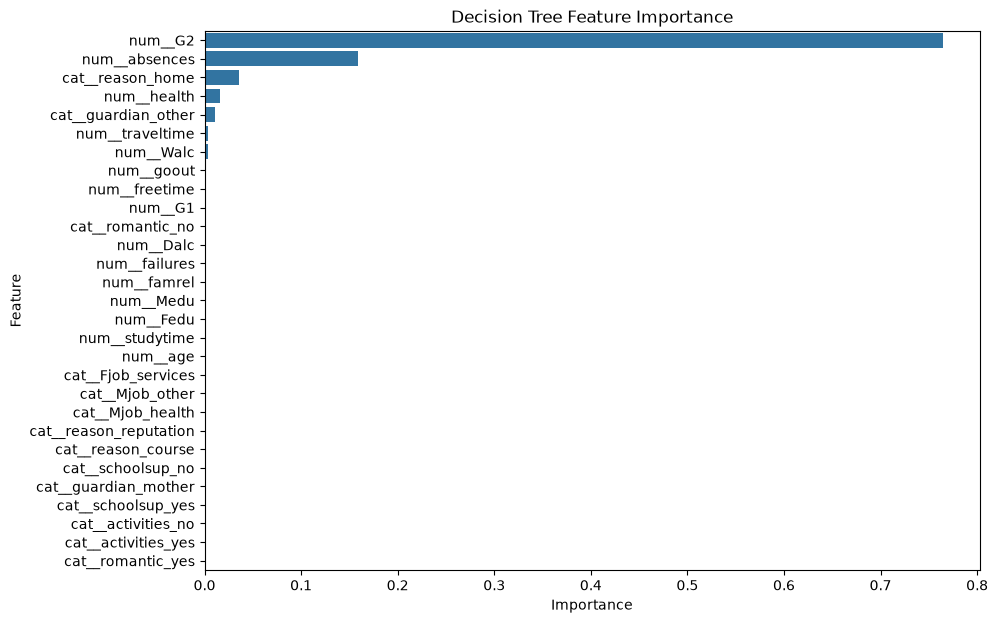

In [16]:
# Get feature importance from trained decision tree
importance = best_model.named_steps["regressor"].feature_importances_

# Create dataframe
importance_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance": importance
})

# Sort in descending order
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

# Plot
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.show()

In [12]:
# Predictions
y_train_pred = best_model.predict(X_train)

y_test_pred = best_model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [13]:
# Training metrics
train_mae = mean_absolute_error(y_train, y_train_pred)

train_mse = mean_squared_error(y_train, y_train_pred)

train_rmse = np.sqrt(train_mse)

train_r2 = r2_score(y_train, y_train_pred)


# Testing metrics
test_mae = mean_absolute_error(y_test, y_test_pred)

test_mse = mean_squared_error(y_test, y_test_pred)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(y_test, y_test_pred)


# Display results
results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],

    "Training": [
        train_mae,
        train_mse,
        train_rmse,
        train_r2
    ],

    "Testing": [
        test_mae,
        test_mse,
        test_rmse,
        test_r2
    ]
})

print(results)

     Metric  Training   Testing
0       MAE  0.515028  1.353702
1       MSE  0.714191  5.797153
2      RMSE  0.845098  2.407728
3  R2 Score  0.965998  0.717282


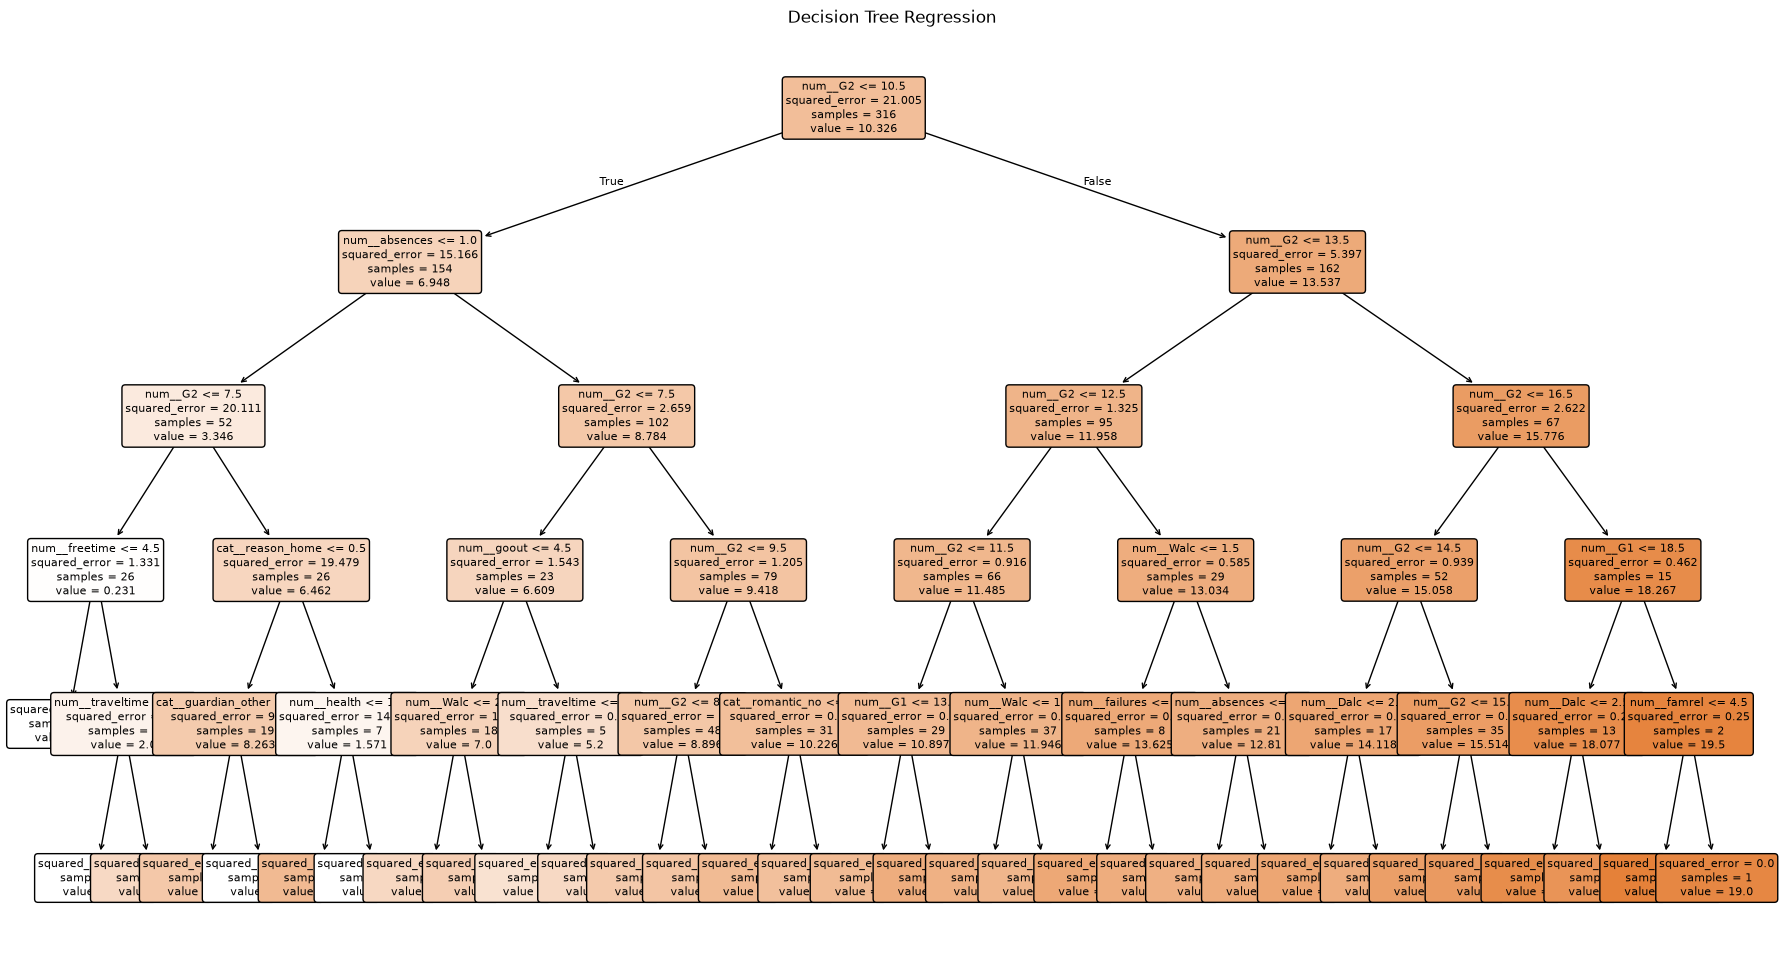

In [14]:
plt.figure(figsize=(22, 12))

plot_tree(
    best_model.named_steps["regressor"],
    feature_names=selected_features,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regression")
plt.show()

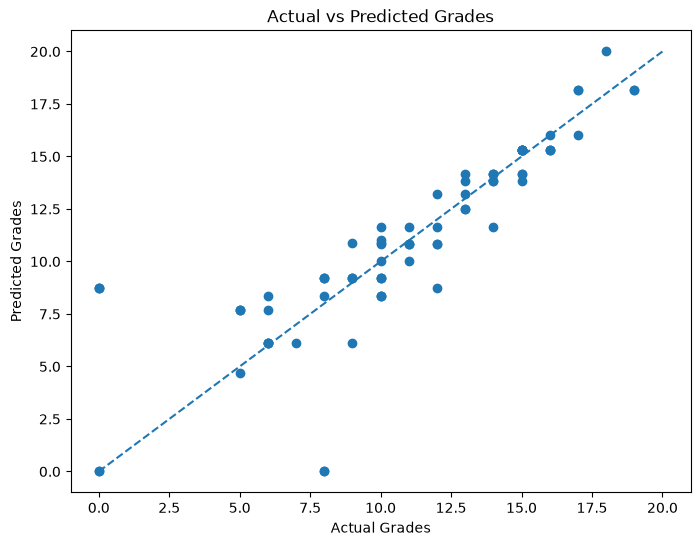

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title("Actual vs Predicted Grades")

plt.show()